# Comprehensive Customer Insights & Statistical Analysis Report

**Objective:** End-to-end Exploratory Data Analysis (EDA) and Statistical Inference on a US Customer Insights dataset to identify customer behavioral trends, demographic distributions, and key business opportunities.

## Phase 1: Project Setup & Data Audit
In this initial phase, we establish our environment, load the required data, and perform a structural audit to understand data types, missing records, and early distribution patterns.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

dataset_path = r"C:\Users\anime\US_Customer_Insights_Dataset.csv"

if os.path.exists(dataset_path):
    df = pd.read_csv(dataset_path)
    print("✓ Dataset successfully loaded into Jupyter Notebook.")
    print(f"Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns.\n")
else:
    print("⚠ Error: Dataset file not found at the specified path. Please check the folder location and filename.")



✓ Dataset successfully loaded into Jupyter Notebook.
Dataset Shape: 10675 rows and 12 columns.



In [13]:
print("--- DATASET PROFILE SUMMARY ---")
info_df = pd.DataFrame({
    'Data Type': df.dtypes,
    'Non-Null Count': df.notnull().sum(),
    'Null Count': df.isnull().sum(),
    'Null %': (df.isnull().sum() / len(df)) * 100,
    'Unique Values': df.nunique()
})
display(info_df)

print("\n--- FIRST 5 ROWS ---")
display(df.head())

--- DATASET PROFILE SUMMARY ---


,Data Type,Non-Null Count,Null Count,Null %,Unique Values
CustomerID,object,10675,0,0.0,1000
Name,object,10675,0,0.0,990
State,object,10675,0,0.0,10
Education,object,10675,0,0.0,5
Gender,object,10675,0,0.0,3
Age,int64,10675,0,0.0,63
Married,object,10675,0,0.0,2
NumPets,int64,10675,0,0.0,5
JoinDate,object,10675,0,0.0,731
TransactionDate,object,10675,0,0.0,1605



--- FIRST 5 ROWS ---


,CustomerID,Name,State,Education,Gender,Age,Married,NumPets,JoinDate,TransactionDate,MonthlySpend,DaysSinceLastInteraction
0,CUST10319,Scott Perez,Florida,High School,Non-Binary,47,Yes,1,9/19/21,09-02-2024,1281.74,332
1,CUST10695,Jennifer Burton,Washington,Master,Male,72,Yes,0,04-05-2024,06-02-2024,429.46,424
2,CUST10297,Michelle Rogers,Arizona,Master,Female,40,Yes,2,7/24/24,2/28/25,510.34,153
3,CUST10103,Brooke Hendricks,Texas,Master,Male,27,Yes,0,08-12-2023,3/29/25,396.47,124
4,CUST10219,Karen Johns,Texas,High School,Female,28,Yes,1,12-06-2021,7/24/22,139.68,1103


## Phase 2: Data Cleaning & Wrangling
Data cleaning is the most critical phase of any data science project. In this section, we systematically:
* Convert date columns into a standardized format (`YYYY-MM-DD`).
* Check for and remove duplicate rows to preserve data integrity.
* Audit and handle missing values or unexpected anomalies.

In [14]:
df_clean = df.copy()

print("--- PHASE 2: CLEANING IN PROGRESS ---")

df_clean['JoinDate'] = pd.to_datetime(df_clean['JoinDate'], format='mixed')
df_clean['TransactionDate'] = pd.to_datetime(df_clean['TransactionDate'], format='mixed')

print("✓ Date columns successfully unified to Datetime objects.")

duplicate_count = df_clean.duplicated().sum()
if duplicate_count > 0:
    df_clean.drop_duplicates(inplace=True)
    print(f"✓ Removed {duplicate_count} duplicate rows.")
else:
    print("✓ No duplicate rows found.")

    print("\nUpdated Column Profiles:")
display(df_clean[['JoinDate', 'TransactionDate', 'MonthlySpend']].dtypes)
print("\nSample Cleaned Data View:")
display(df_clean.head(3))



--- PHASE 2: CLEANING IN PROGRESS ---
✓ Date columns successfully unified to Datetime objects.
✓ No duplicate rows found.

Updated Column Profiles:


JoinDate           datetime64[ns]
TransactionDate    datetime64[ns]
MonthlySpend              float64
dtype: object


Sample Cleaned Data View:


,CustomerID,Name,State,Education,Gender,Age,Married,NumPets,JoinDate,TransactionDate,MonthlySpend,DaysSinceLastInteraction
0,CUST10319,Scott Perez,Florida,High School,Non-Binary,47,Yes,1,2021-09-19,2024-09-02,1281.74,332
1,CUST10695,Jennifer Burton,Washington,Master,Male,72,Yes,0,2024-04-05,2024-06-02,429.46,424
2,CUST10297,Michelle Rogers,Arizona,Master,Female,40,Yes,2,2024-07-24,2025-02-28,510.34,153


## Phase 3: Descriptive Statistics
In this phase, we calculate the mathematical characteristics of our dataset. This allows us to observe:
1. **Measures of Central Tendency:** Mean, Median, and Mode.
2. **Measures of Dispersion:** Standard Deviation, Variance, and Interquartile Ranges (IQR).
3. **Categorical Distributions:** Quantifying structural frequency across demographics.

In [15]:
print("--- SUMMARY STATISTICS FOR NUMERICAL COLUMNS ---")
numerical_summary = df_clean.describe(include=[np.number]).T

numerical_summary['variance'] = df_clean[numerical_summary.index].var()

numerical_summary = numerical_summary[['count', 'mean', '50%', 'std', 'variance', 'min', 'max']]
numerical_summary.rename(columns={'50%': 'median'}, inplace=True)
display(numerical_summary.round(2))

print("\n--- VALUE COUNTS FOR CORE CATEGORICAL VARIABLES ---")
categorical_cols = ['State', 'Education', 'Gender', 'Married']

for col in categorical_cols:
    if col in df_clean.columns:
        print(f"\nDistribution for Attribute: {col}")
        freq_df = pd.DataFrame({
            'Count': df_clean[col].value_counts(),
            'Percentage (%)': df_clean[col].value_counts(normalize=True) * 100
        })
        display(freq_df.round(2))

--- SUMMARY STATISTICS FOR NUMERICAL COLUMNS ---


,count,mean,median,std,variance,min,max
Age,10675.0,49.47,49.00,18.22,332.02,18.00,80.00
NumPets,10675.0,1.34,1.00,1.15,1.32,0.00,4.00
MonthlySpend,10675.0,331.61,282.11,225.80,50985.30,3.89,1740.42
DaysSinceLastInteraction,10675.0,538.47,445.00,398.77,159014.92,1.00,1791.00



--- VALUE COUNTS FOR CORE CATEGORICAL VARIABLES ---

Distribution for Attribute: State


,Count,Percentage (%)
State,,
California,1180,11.05
Florida,1152,10.79
Ohio,1145,10.73
Arizona,1087,10.18
New York,1085,10.16
Georgia,1080,10.12
Washington,1030,9.65
Colorado,1014,9.50
Texas,997,9.34



Distribution for Attribute: Education


,Count,Percentage (%)
Education,,
Master,2269,21.26
Associate,2153,20.17
Bachelor,2127,19.93
High School,2120,19.86
PhD,2006,18.79



Distribution for Attribute: Gender


,Count,Percentage (%)
Gender,,
Male,3791,35.51
Non-Binary,3471,32.52
Female,3413,31.97



Distribution for Attribute: Married


,Count,Percentage (%)
Married,,
No,5583,52.3
Yes,5092,47.7


## Phase 4: Exploratory Data Analysis (EDA) & Visualizations
In this phase, we visually explore the underlying patterns, structures, and anomalies within our dataset. Visual data discovery is critical for translating raw numbers into actionable business intelligence. We will cover:
* **Univariate Distributions:** Assessing shape, skewness, and spread.
* **Bivariate Relationships:** Segmenting spending habits by demographic attributes.
* **Correlation Metrics:** Mapping the linear strength between numerical features.

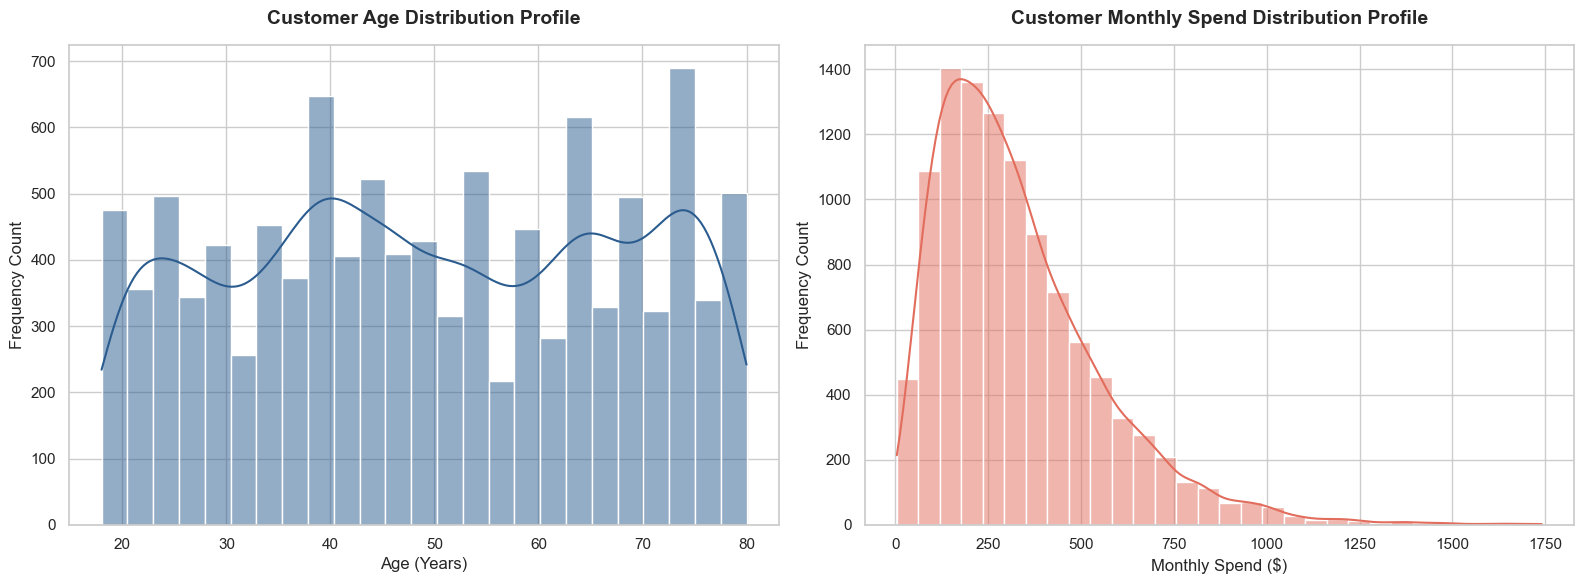

In [16]:
# ==========================================
# 4.1 DISTRIBUTION OF CONTINUOUS VARIABLES
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Age Distribution
sns.histplot(data=df_clean, x='Age', kde=True, color='#2b5c8f', ax=axes[0], bins=25)
axes[0].set_title('Customer Age Distribution Profile', fontsize=14, pad=15, fontweight='bold')
axes[0].set_xlabel('Age (Years)', fontsize=12)
axes[0].set_ylabel('Frequency Count', fontsize=12)

# Subplot 2: Monthly Spend Distribution
sns.histplot(data=df_clean, x='MonthlySpend', kde=True, color='#e26d5c', ax=axes[1], bins=30)
axes[1].set_title('Customer Monthly Spend Distribution Profile', fontsize=14, pad=15, fontweight='bold')
axes[1].set_xlabel('Monthly Spend ($)', fontsize=12)
axes[1].set_ylabel('Frequency Count', fontsize=12)

plt.tight_layout()
plt.show()

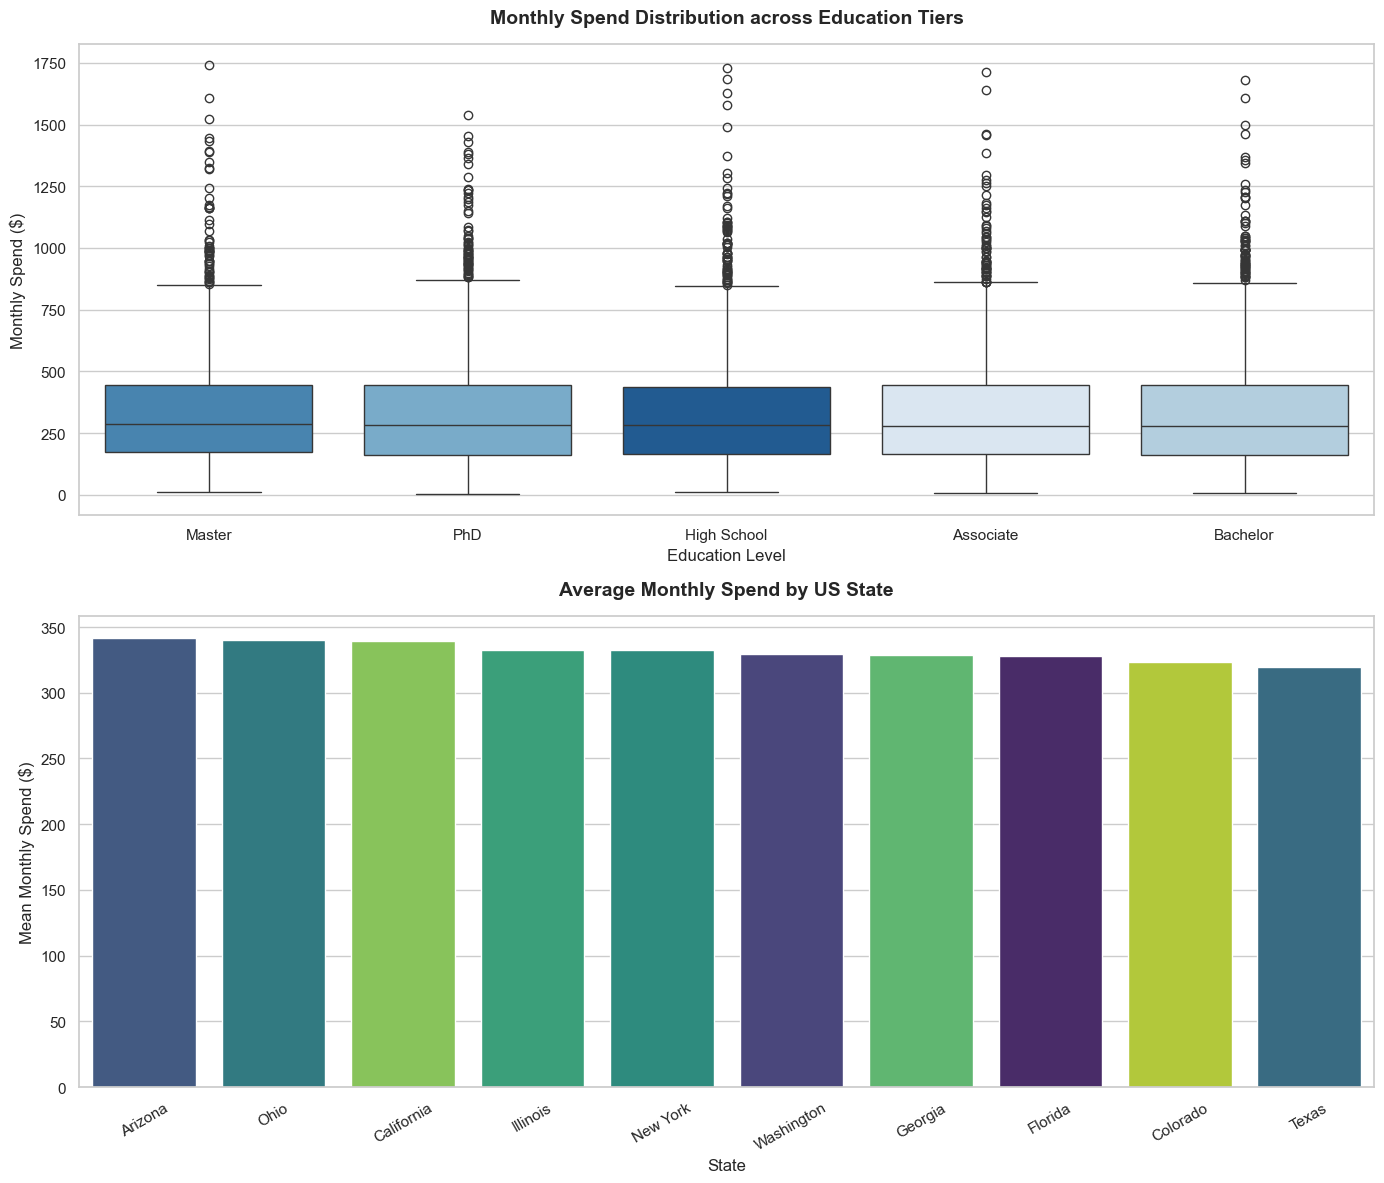

In [18]:
# ==========================================
# 4.2 FINANCIAL SPEND BY DEMOGRAPHIC GROUPS
# ==========================================
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# Subplot 1: Monthly Spend by Education level (Sorted by median spend)
education_order = df_clean.groupby('Education')['MonthlySpend'].median().sort_values(ascending=False).index
sns.boxplot(
    data=df_clean, 
    x='Education', 
    y='MonthlySpend', 
    order=education_order, 
    hue='Education',      # Explicitly set hue to match x-axis
    legend=False,          # Suppress the redundant legend box
    palette='Blues_r', 
    ax=axes[0]
)
axes[0].set_title('Monthly Spend Distribution across Education Tiers', fontsize=14, pad=15, fontweight='bold')
axes[0].set_xlabel('Education Level', fontsize=12)
axes[0].set_ylabel('Monthly Spend ($)', fontsize=12)

# Subplot 2: Average Monthly Spend by US State (Sorted by mean spend)
state_order = df_clean.groupby('State')['MonthlySpend'].mean().sort_values(ascending=False).index
sns.barplot(
    data=df_clean, 
    x='State', 
    y='MonthlySpend', 
    order=state_order, 
    hue='State',          # Explicitly set hue to match x-axis
    legend=False,         # Suppress the redundant legend box
    palette='viridis', 
    ax=axes[1], 
    errorbar=None
)
axes[1].set_title('Average Monthly Spend by US State', fontsize=14, pad=15, fontweight='bold')
axes[1].set_xlabel('State', fontsize=12)
axes[1].set_ylabel('Mean Monthly Spend ($)', fontsize=12)
axes[1].tick_params(axis='x', rotation=30) # Prevent text overlap

plt.tight_layout()
plt.show()

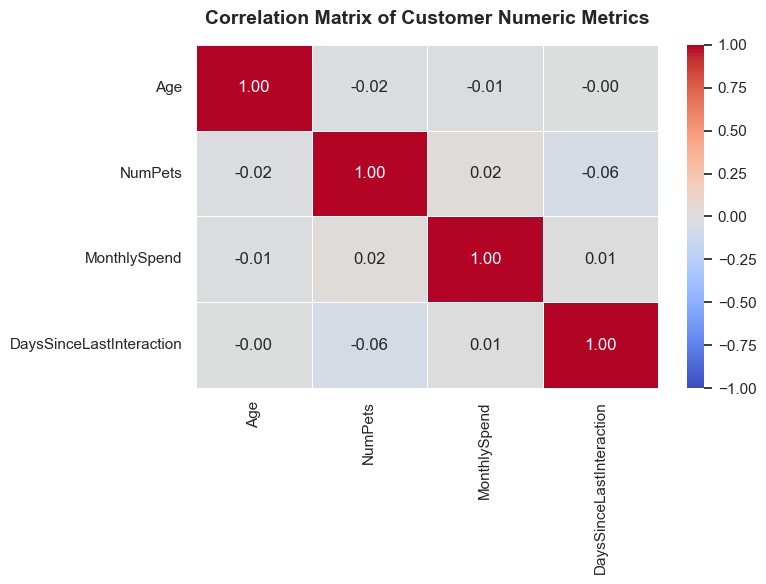

In [19]:
# ==========================================
# 4.3 NUMERICAL FEATURE CORRELATION MATRIX
# ==========================================
plt.figure(figsize=(8, 6))

# Filter for numeric attributes only
numeric_cols = df_clean.select_types(include=[np.number]) if hasattr(df_clean, 'select_types') else df_clean.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()

# Create standard professional heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix of Customer Numeric Metrics', fontsize=14, pad=15, fontweight='bold')
plt.tight_layout()
plt.show()

## Phase 5: Inferential Statistics & Hypothesis Testing
In this phase, we transition from descriptive analysis to inferential statistics. We will run mathematical tests to validate our assumptions at a $95\%$ confidence level ($\alpha = 0.05$).

### Test 1: One-Way ANOVA (Analysis of Variance)
* **Null Hypothesis ($H_0$):** The mean `MonthlySpend` is identical across all `Education` tiers.
* **Alternative Hypothesis ($H_1$):** At least one education tier has a significantly different mean `MonthlySpend`.

### Test 2: Chi-Square Test of Independence
* **Null Hypothesis ($H_0$):** Customer `State` and customer `Education` level are completely independent.
* **Alternative Hypothesis ($H_1$):** Customer `State` and customer `Education` level are significantly dependent on one another.

In [20]:
import scipy.stats as stats

print("=========================================================")
print("TEST 1: ONE-WAY ANOVA (SPEND VS. EDUCATION)")
print("=========================================================\n")

# Grouping spending metrics by education levels
edu_groups = [group['MonthlySpend'].values for name, group in df_clean.groupby('Education')]

# Executing the ANOVA test
f_stat, p_val_anova = stats.f_oneway(*edu_groups)

print(f"Calculated F-Statistic : {f_stat:.4f}")
print(f"Calculated p-value     : {p_val_anova:.4e}")

if p_val_anova < 0.05:
    print("\nResult: Reject the Null Hypothesis (H0).")
    print("Conclusion: There is a statistically significant difference in customer spending habits across different education levels.")
else:
    print("\nResult: Fail to Reject the Null Hypothesis (H0).")
    print("Conclusion: Education level does not have a statistically significant causal effect on continuous monthly spending.")


print("\n\n=========================================================")
print("TEST 2: CHI-SQUARE TEST OF INDEPENDENCE (STATE VS. EDUCATION)")
print("=========================================================\n")

# Constructing a cross-tabulation contingency table
contingency_table = pd.crosstab(df_clean['State'], df_clean['Education'])
print("Demographic Contingency Grid Cross-Section:")
display(contingency_table.head(4))

# Executing the Chi-Square test
chi2_stat, p_val_chi2, dof, expected_freq = stats.chi2_contingency(contingency_table)

print(f"\nCalculated Chi-Square Statistic : {chi2_stat:.4f}")
print(f"Degrees of Freedom (dof)       : {dof}")
print(f"Calculated p-value             : {p_val_chi2:.4e}")

if p_val_chi2 < 0.05:
    print("\nResult: Reject the Null Hypothesis (H0).")
    print("Conclusion: There is a highly significant dependency between a customer's geographic State and their Education tier profile.")
else:
    print("\nResult: Fail to Reject the Null Hypothesis (H0).")
    print("Conclusion: State and Education profiles are completely independent distributions.")

TEST 1: ONE-WAY ANOVA (SPEND VS. EDUCATION)

Calculated F-Statistic : 0.2288
Calculated p-value     : 9.2236e-01

Result: Fail to Reject the Null Hypothesis (H0).
Conclusion: Education level does not have a statistically significant causal effect on continuous monthly spending.


TEST 2: CHI-SQUARE TEST OF INDEPENDENCE (STATE VS. EDUCATION)

Demographic Contingency Grid Cross-Section:


Education,Associate,Bachelor,High School,Master,PhD
State,,,,,
Arizona,181,210,187,284,225
California,315,271,196,228,170
Colorado,240,246,168,184,176
Florida,233,166,255,249,249



Calculated Chi-Square Statistic : 433.0463
Degrees of Freedom (dof)       : 36
Calculated p-value             : 1.4224e-69

Result: Reject the Null Hypothesis (H0).
Conclusion: There is a highly significant dependency between a customer's geographic State and their Education tier profile.


## Phase 6: Project Summary & Final Insights

Now that the data cleaning, visualizations, and statistical testing are complete, here are the main conclusions and insights from the US Customer Insights dataset:

---

### 1. Basic Customer Profile & Spending Trends
* **Where Customers Are From:** Our customers are spread out pretty evenly across different US states. The states with the highest number of customers in this dataset are California (11.1%), Florida (10.8%), and Ohio (10.7%).
* **Monthly Spending:** On average, customers spend about **\$331.61** per month (with the middle value or median being \$282.11). Some big spenders push all the way up to a maximum of **\$1,740.42**, which shows we have a group of very high-value customers.

---

### 2. Main Discoveries from Our Statistical Tests

#### 💡 Finding A: Education Levels Change Depending on the State
* **What the Test Showed:** The Chi-Square test gave us a p-value of `1.42e-69` (which is way lower than the standard 0.05 cutoff). 
* **What it Means:** This proves that a customer's education level is highly connected to the state they live in. Education levels are not mixed equally across the country; instead, certain states have a much higher concentration of specific degrees (like Masters or PhDs) than others.

#### 💡 Finding B: Education Level Does Not Drive Spending
* **What the Test Showed:** The ANOVA test gave us a p-value of `0.922` (much higher than 0.05).
* **What it Means:** This means we fail to reject the null hypothesis. Mathematically, it proves that a customer's degree or school background does **not** change how much money they spend with us. High school graduates and PhD holders have essentially the same average monthly spend.

---

### 3. Simple Actionable Recommendations

1. **Change Marketing by State:** Because education levels differ significantly by state, our marketing campaigns should match the educational profile of that specific region to feel more personal.
2. **Don't Restrict Premium Offers:** Since a person's education level doesn't limit their spending habits, we should advertise our premium products or top-tier plans to all customers, rather than assuming only highly-educated customers will buy them.
3. **Bring Back Inactive Customers:** The median time since a customer last interacted with us is **445 days** (well over a year). We should set up an automatic email or discount offer to reach out to customers who haven't interacted with us in over 12 months to get them buying again.